### SeRNN block taken for our approach :

#### Block 1 — Imports

Taken from the demo (cells 3, 4, 5). Removed: `to_categorical`, which the demo imports but never uses.

In [2]:
# [DEMO cells 3 + 5]
import os                                          # used by block 6 (outputs folder)
import numpy as np
import pandas as pd                                # used by mazeGeneratorI
import scipy.spatial.distance                      # used by SE1 (distance matrix)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D           # used by SE1.visualise_neuron_structure
import bct                                         # Brain Connectivity Toolbox, used by block 7b [DEMO cell 26]
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.regularizers import Regularizer
from tensorflow.python.keras import backend       # used by SE1 (backend.cast_to_floatx)

# [DEMO cell 4] versions, should match requirements.txt
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| numpy", np.__version__)

tensorflow 2.21.0 | keras 3.15.0 | numpy 2.2.6


#### Block 2 — Hyperparameters

Every argument the demo passes, in one place. Source tags: `[DEMO cell N]` = seRNN_demo.ipynb

In [3]:
# Seeds [DEMO cell 6]
NP_SEED = 1829         # numpy seed 
TF_SEED = 9492         # tensorflow seed

# Task: one-step inference maze [DEMO cell 11]
GOAL_STEPS = 20        # goal presentation
DELAY_STEPS = 10       # delay
CHOICE_STEPS = 20      # choices presentation
N_TRAIN = 5120         # problems per epoch
N_TEST = 2560
N_VAL = 2560
BATCH_SIZE = 128

# Network [DEMO cell 21]
N_UNITS = 100
GRID = (5, 5, 4)       # SE1 default network_structure: 100 units on a 5x5x4 grid
INPUT_NOISE_STD = 0.05
N_OUT = 4              # Dense(4): 4 directions (Left, Up, Right, Down)

# Training [DEMO cell 23-24] : Adam with default parameters (lr 0.001), 10 epochs
EPOCHS = 10

# Regularisation strength γ. TO BE AWARE Because:
#   0.5 [DEMO cell 20] · 0.3 [CAPSULE seRNN_demo] · 0.08 [PAPER Fig. 2e, example network]
GAMMA_SERNN = 0.22     # Fig. 6c sweet-spot centre: 22 % of linspace(1e-6, 1, 1001)
GAMMA_L1 = 0.0066      # same position: 22 % of linspace(1e-7, 0.03, 1001)

# Selection PAPER: keep networks with accuracy > 90 %
ACC_MIN = 0.9
# 10 networks per group, one seed each. Each list = the first 10 seeds (in 0..31) whose network passes ACC_MIN
# Seeds are not paired across groups, as in the paper.
SEEDS = {'seRNN': [2, 5, 7, 10, 11, 13, 15, 22, 25, 31],
         'L1':    [1, 7, 8, 9, 10, 11, 12, 13, 18, 19]}

# Structure of W_rec (block 7b) [PAPER Methods 'Topological analysis']
TOP_PROP = 0.10        # small-worldness: keep the top 10 % of |w| (diagonal excluded) [PAPER] [DEMO cell 28] [CAPSULE thr = 0.1]
MOD_GAMMA = 1          # modularity resolution parameter [PAPER] [CAPSULE modularity_und default]
N_NULL = 1000          # random graphs for small-worldness [PAPER] [DEMO cell 33]
NULL_SEED = 0

# Where results are written
OUT_DIR = "outputs"

# [DEMO cell 6]
np.random.seed(NP_SEED)
tf.random.set_seed(TF_SEED)
tf.config.experimental.enable_op_determinism()

#### Block 3 — Task: the 16 problems

The demo trains on 8 problems, the paper's *regular* task. The paper lists all 16 possible problems in Extended Data Table 1 ("harder version", Supp. Fig. 8). Stimulus A = goal, stimulus B = 2 possible directions, correct choice = the direction that moves closer to the goal.

Block 3a = the demo generator with 2 changes, marked `MODIFIED`: the problem list (16 instead of 8) and `randint(0, 8)` → `randint(0, 16)`. Same encoding: 8 inputs, 4 outputs.

Block 3b = build the datasets [DEMO cells 11–12] and look at them.

In [4]:
# [DEMO cell 9] mazeGeneratorI, copied as is except the lines marked MODIFIED (16 problems instead of 8)
class mazeGeneratorI():
    '''
    Objects of the mazeGeneratorI class can create numpy and tf datasets of the first choice of the maze task.
    Task structure:
        Goal presentation, followed by delay period, followed by choice options.
    Response:
        One response required from agent at end of episode. Direction (Left, Up, Right, Down) of first step.
    Encoding:
        Both observations and labels are OneHot encoded.
    Usage:
        The two only function a user should need to access are "construct_numpy_data" and "construct_tf_data"
    Options:
        Both data construction methods have an option to shuffle the labels of data.
        The numpy data construction method allows to also return the maze identifiers.
    '''
    def __init__(self, goal_presentation_steps, delay_steps, choices_presentation_steps):
        self.version = 'v1.2.0'

        # Import variables defining episode
        self.goal_presentation_steps = goal_presentation_steps
        self.delay_steps = delay_steps
        self.choices_presentation_steps = choices_presentation_steps

        # Construct mazes dataframe
        ## Add encoded versions of the goal / choices presentations and the next step response
        self.mazesdf = self.import_maze_dic()
        self.mazesdf['Goal_Presentation'] = self.mazesdf['goal'].map({
            7:np.concatenate((np.array([1,0,0,0]),np.repeat(0,4))),
            9:np.concatenate((np.array([0,1,0,0]),np.repeat(0,4))),
            17:np.concatenate((np.array([0,0,1,0]),np.repeat(0,4))),
            19:np.concatenate((np.array([0,0,0,1]),np.repeat(0,4)))})
        self.mazesdf['Choices_Presentation']=self.mazesdf['ChoicesCategory'].map(lambda x: self.encode_choices(x=x))
        self.mazesdf['Step_Encoded']=self.mazesdf['NextFPmap'].map(lambda x: self.encode_next_step(x=x))

    def construct_numpy_data(self, number_of_problems, return_maze_identifiers = False, np_shuffle_data = False):
        # Create a new column which hold the vector for each problem
        self.mazesdf['Problem_Vec']=self.mazesdf.apply(lambda x: self.create_problem_observation(row= x,goal_presentation_steps= self.goal_presentation_steps,delay_steps= self.delay_steps,choices_presentation_steps= self.choices_presentation_steps), axis=1)
        # Set a random order of maze problems for the current session
        self.mazes_order = np.random.randint(0,len(self.mazesdf),number_of_problems)   # MODIFIED: was randint(0,8,...)

        # Create vectors, holding observations and labels
        session_observation =np.array([])
        session_labels = np.array([])
        for i in self.mazes_order:
            session_observation = np.append(session_observation,self.mazesdf.iloc[i]['Problem_Vec'])
            session_labels = np.append(session_labels,self.mazesdf.iloc[i]['Step_Encoded'])

        # Reshape vectors to fit network observation and response space
        session_length = self.goal_presentation_steps + self.delay_steps + self.choices_presentation_steps
        session_observation = np.reshape(session_observation, (-1,session_length,8)).astype('float32')
        session_labels = np.reshape(session_labels, (-1,4)).astype('float32')

        # If np_shuffle_data == 'Labels, the order of labels is shuffled to randomise correct answers
        if np_shuffle_data == 'Labels':
          shuffle_generator = np.random.default_rng(38446)
          shuffle_generator.shuffle(session_labels,axis=0)

        # If return_maze_identifiers == 'IDs', return the array with maze IDs alongside the regular returns (observations, labels)
        if return_maze_identifiers == 'IDs':
          return session_observation, session_labels, self.mazes_order

        return session_observation, session_labels

    def construct_tf_data(self, number_of_problems, batch_size, tf_shuffle_data = False):
        # Create dataset as described by numpy dataset function and transform it into a TF dataset
        npds, np_labels = self.construct_numpy_data(number_of_problems=number_of_problems, np_shuffle_data = tf_shuffle_data)
        tfdf = tf.data.Dataset.from_tensor_slices((npds, np_labels))
        tfdf = tfdf.batch(batch_size)
        return tfdf

    def reset_construction_params(self, goal_presentation_steps, delay_steps, choices_presentation_steps):
        self.goal_presentation_steps = goal_presentation_steps
        self.delay_steps = delay_steps
        self.choices_presentation_steps = choices_presentation_steps

    def import_maze_dic(self, mazeDic=None):
        if mazeDic == None:
            # Set up dataframe with first choices of maze task
            ## The dictionary was generated using MazeMetadata.py (v1.0.0) and the following call:
            ### mazes.loc[(mazes['Nsteps']==2)&(mazes['ChoiceNo']=='ChoiceI')][['goal','ChoicesCategory','NextFPmap']].reset_index(drop=True).to_dict()
            # MODIFIED: the 16 problems of [PAPER Extended Data Table 1] instead of the demo's 8.
            # Goal codes as in the demo: 9 = (Right, up), 19 = (Right, down), 7 = (Left, up), 17 = (Left, down).
            # Order = ED Table 1 problems 1..16. Regular task (the demo's 8) = problems 2, 4, 5, 8, 9, 12, 14, 16.
            self.mazesDic = {'goal': {0: 9, 1: 9, 2: 9, 3: 9, 4: 19, 5: 19, 6: 19, 7: 19,
                                      8: 7, 9: 7, 10: 7, 11: 7, 12: 17, 13: 17, 14: 17, 15: 17},
            'ChoicesCategory': {0: 'lr', 1: 'rd', 2: 'ud', 3: 'ul',
                                4: 'lr', 5: 'ur', 6: 'ud', 7: 'ld',
                                8: 'lr', 9: 'ld', 10: 'ud', 11: 'ur',
                                12: 'lr', 13: 'ul', 14: 'ud', 15: 'rd'},
            'NextFPmap': {0: 'r', 1: 'r', 2: 'u', 3: 'u',
                          4: 'r', 5: 'r', 6: 'd', 7: 'd',
                          8: 'l', 9: 'l', 10: 'u', 11: 'u',
                          12: 'l', 13: 'l', 14: 'd', 15: 'd'}}
        else:
            self.mazesDic = mazesDic

        # Create and return dataframe
        return pd.DataFrame(self.mazesDic)

    def encode_choices(self, x):
        # Helper function to create the observation vector for choice periods
        choices_sec = np.repeat(0,4)
        choicesEncoding = pd.Series(list(x))
        choicesEncoding = choicesEncoding.map({'l':1,'u':2,'r':3,'d':4})
        for encodedChoice in choicesEncoding:
            choices_sec[encodedChoice-1]=1
        return np.concatenate((np.repeat(0,4),choices_sec))

    def encode_next_step(self, x):
        # Helper function to change the response / action to a OneHot encoded vector
        step_sec = np.repeat(0,4)
        stepEncoding = pd.Series(list(x))
        stepEncoding = stepEncoding.map({'l':1,'u':2,'r':3,'d':4})
        for encodedStep in stepEncoding:
            step_sec[encodedStep-1]=1
        return step_sec

    def create_problem_observation(self, row, goal_presentation_steps, delay_steps, choices_presentation_steps):
        # Helper function to create one vector describing the entire outline of one maze problem (Goal presentation, Delay Period, and Choices Presentation)
        goal_vec = np.tile(row['Goal_Presentation'], goal_presentation_steps)
        delay_vec = np.tile(np.repeat(0,8), delay_steps)
        choices_vec = np.tile(row['Choices_Presentation'], choices_presentation_steps)
        problem_vec = np.concatenate((goal_vec,delay_vec,choices_vec))
        return problem_vec

    def __repr__(self):
        return '\n'.join([
            f'Maze DataSet Generator',
            f'Goal Presentation Steps: {self.goal_presentation_steps}',
            f'Delay Steps: {self.delay_steps}',
            f'Choices Presentation Steps: {self.choices_presentation_steps}'])


train: times each of the 16 problems is drawn: [334 310 340 315 311 324 355 331 332 305 310 302 329 305 309 308]


,goal (stimulus A),choices (stimulus B),correct answer,in demo (regular task)
problem,,,,
1,right-up,left / right,right,False
2,right-up,right / down,right,True
3,right-up,up / down,up,False
4,right-up,up / left,up,True
5,right-down,left / right,right,True
6,right-down,up / right,right,False
7,right-down,up / down,down,False
8,right-down,left / down,down,True
9,left-up,left / right,left,True


inputs (128, 50, 8) | labels (128, 4)


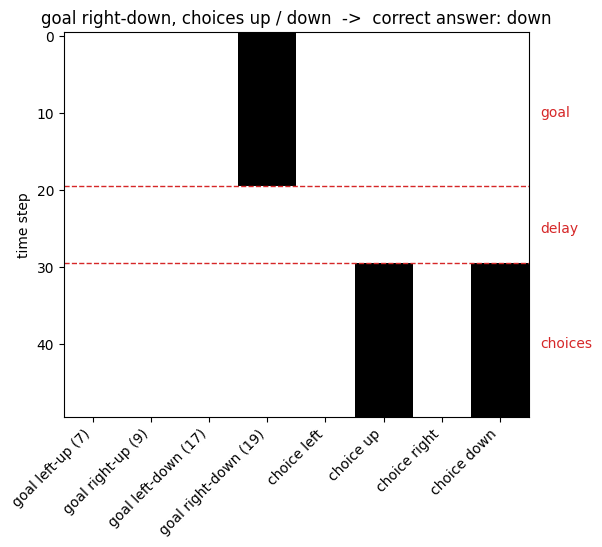

In [5]:
# [DEMO cell 11] build the datasets
np.random.seed(NP_SEED)   # re-seed here: the datasets depend on numpy's random state, so re-running this cell
                          # (or running cells out of order) must always give the same data
gen = mazeGeneratorI(goal_presentation_steps=GOAL_STEPS, delay_steps=DELAY_STEPS, choices_presentation_steps=CHOICE_STEPS)
tfdf = gen.construct_tf_data(number_of_problems=N_TRAIN, batch_size=BATCH_SIZE)
print("train: times each of the 16 problems is drawn:", np.bincount(gen.mazes_order, minlength=16))
tfdf_test = gen.construct_tf_data(number_of_problems=N_TEST, batch_size=BATCH_SIZE)
tfdf_val = gen.construct_tf_data(number_of_problems=N_VAL, batch_size=BATCH_SIZE)

# Readable names for the demo encoding (mazeGeneratorI.__init__).
# Goal codes = cells of a 5x5 maze numbered 1..25 row by row; the agent starts at the centre cell 13.
GOAL_NAMES = {7: 'left-up', 9: 'right-up', 17: 'left-down', 19: 'right-down'}
DIR_NAMES = {'l': 'left', 'u': 'up', 'r': 'right', 'd': 'down'}
INPUT_NAMES = ['goal left-up (7)', 'goal right-up (9)', 'goal left-down (17)', 'goal right-down (19)',
               'choice left', 'choice up', 'choice right', 'choice down']

# The 16 problems, as in [PAPER Extended Data Table 1]
problems = pd.DataFrame({
    'problem': range(1, 17),
    'goal (stimulus A)': gen.mazesdf['goal'].map(GOAL_NAMES),
    'choices (stimulus B)': gen.mazesdf['ChoicesCategory'].map(lambda s: ' / '.join(DIR_NAMES[c] for c in s)),
    'correct answer': gen.mazesdf['NextFPmap'].map(DIR_NAMES),
    'in demo (regular task)': [p in (2, 4, 5, 8, 9, 12, 14, 16) for p in range(1, 17)]})
display(problems.set_index('problem'))   # problem number = row label (no extra 0..15 index)

# [DEMO cell 12] one batch: inputs (batch, time steps, 8), labels (batch, 4)
example_data = next(iter(tfdf))
print("inputs", example_data[0].shape, "| labels", example_data[1].shape)

# One example trial. Rows = time steps, columns = the 8 inputs. Black = 1, white = 0.
x, y = example_data[0][0].numpy(), example_data[1][0].numpy()
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(x, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
ax.set_xticks(range(8)); ax.set_xticklabels(INPUT_NAMES, rotation=45, ha='right')
ax.set_ylabel('time step')
for t in (GOAL_STEPS, GOAL_STEPS + DELAY_STEPS):
    ax.axhline(t - 0.5, color='tab:red', lw=1, ls='--')
for t0, t1, name in [(0, GOAL_STEPS, 'goal'), (GOAL_STEPS, GOAL_STEPS + DELAY_STEPS, 'delay'),
                     (GOAL_STEPS + DELAY_STEPS, GOAL_STEPS + DELAY_STEPS + CHOICE_STEPS, 'choices')]:
    ax.text(7.7, (t0 + t1) / 2, name, va='center', color='tab:red')
goal = INPUT_NAMES[x[0, :4].argmax()].split(' ')[1]
choices = [INPUT_NAMES[4 + k].split(' ')[1] for k in np.flatnonzero(x[-1, 4:])]
ax.set_title(f"goal {goal}, choices {' / '.join(choices)}  ->  correct answer: {['left', 'up', 'right', 'down'][y.argmax()]}")
plt.show()

#### Block 4 — Regularisers

Both regularisers act on `W_rec` only (the 100 × 100 recurrent weights).

- **seRNN** [DEMO cells 15–16], copied as is. `SE1` places the 100 units on a 5 × 5 × 4 grid and builds the distance matrix D. `SE1_sWc` (the one used for seRNNs) adds the communicability C. Penalty = γ · Σ |W| ⊙ D ⊙ C.
- **L1** [CAPSULE recording_decoding_demo, cell 8]: `tf.keras.regularizers.L1(γ)`. Penalty = γ · Σ |W|.

Block 4a = the two demo classes. Block 4b = build both regularisers and look at the grid and at D.

In [6]:
# [DEMO cell 15] SE1: L1 weighted by distance.
class SE1(Regularizer):
  """A regulariser for sptially embedded RNNs.
  Applies L1 regularisation to recurrent kernel of
  RNN which is weighted by the distance of units
  in predefined 3D space.
  Calculation:
      se1 * sum[distance_matrix o recurrent_kernel]
  Attributes:
      se1: Float; Weighting of SE1 regularisation term.
      distance_tensor: TF tensor / matrix with cost per
      connection in weight matrix of network.
  """

  def __init__(self, se1=0.01, neuron_num = 100, network_structure = (5,5,4), coordinates_list = None, distance_power = 1, distance_metric = 'euclidean'):
    self.version = 'v1.1.0'
    self.distance_power = distance_power

    # Set SE1 regularisation strength to default of 0.01 if no value given
    se1 = 0.01 if se1 is None else se1
    self._check_penalty_number(se1)

    # Transform regularisation strength to TF's standard float format
    self.se1 = backend.cast_to_floatx(se1)

    # Set up tensor with distance matrix
    ## Set up neurons per dimension
    nx = np.arange(network_structure[0])
    ny = np.arange(network_structure[1])
    nz = np.arange(network_structure[2])

    ## Set up coordinate grid
    [x,y,z] = np.meshgrid(nx,ny,nz)
    self.coordinates = [x.ravel(),y.ravel(),z.ravel()]

    ## Override coordinate grid if one if provided in init
    if coordinates_list!=None:
      self.coordinates = coordinates_list

    ## Check neuron number / number of coordinates
    if (len(self.coordinates[0])==neuron_num)&(len(self.coordinates[1])==neuron_num)&(len(self.coordinates[2])==neuron_num):
      pass
    else:
      raise ValueError('Network / coordinate structure does not match the number of neurons.')

    ## Calculate the euclidean distance matrix
    euclidean_vector = scipy.spatial.distance.pdist(np.transpose(self.coordinates), metric=distance_metric)
    euclidean = scipy.spatial.distance.squareform(euclidean_vector**self.distance_power)
    self.distance_matrix = euclidean.astype('float32')
    self.spatial_cost_matrix = self.distance_matrix

    ## Add minimal cost for recurrent self connection (on diagonal)
    #diag_dist = np.diag(np.repeat(0.1,100)).astype('float32')
    #self.distance_matrix = self.distance_matrix + diag_dist

    ## Create tensor from distance matrix
    self.distance_tensor =  tf.convert_to_tensor(self.distance_matrix)


  def __call__(self, x):
    # Add calculation of loss here.
    # L1 for reference: self.l1 * math_ops.reduce_sum(math_ops.abs(x))
    abs_weight_matrix = tf.math.abs(x)

    #se1_loss = self.se1 * tf.math.multiply(abs_weight_matrix, self.distance_tensor)
    #se1_loss = tf.math.reduce_sum(abs_weight_matrix)
    se1_loss = self.se1 * tf.math.reduce_sum(tf.math.multiply(abs_weight_matrix, self.distance_tensor))

    return se1_loss

  def _check_penalty_number(self, x):
    """check penalty number availability, raise ValueError if failed."""
    if not isinstance(x, (float, int)):
      raise ValueError(('Value: {} is not a valid regularization penalty number, '
                        'expected an int or float value').format(x))

  def visualise_distance_matrix(self):
    plt.imshow(self.distance_matrix)
    plt.colorbar()
    plt.show()

  def visualise_neuron_structure(self):
    fig = plt.figure()
    ax = Axes3D(fig)
    ax.scatter(self.coordinates[0],self.coordinates[1],self.coordinates[2],c='b',marker='.')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    plt.show()

  def get_config(self):
    return {'se1': float(self.se1)}


# [DEMO cell 16] SE1_sWc: SE1 x weighted communicability (the seRNN regulariser).
class SE1_sWc(SE1):
    '''
    Version of SE1 regulariser which combines the spatial and communicability parts in loss function.
    Additional comms_factor scales the communicability matrix.
    The communicability term used here is unbiased weighted communicability:
    Crofts, J. J., & Higham, D. J. (2009). A weighted communicability measure applied to complex brain networks. Journal of the Royal Society Interface, 6(33), 411-414.
    '''
    def __init__(self, se1=0.01, comms_factor = 1, neuron_num = 100, network_structure = (5,5,4), coordinates_list = None, distance_power = 1, distance_metric = 'euclidean'):
      SE1.__init__(self, se1, neuron_num , network_structure , coordinates_list, distance_power , distance_metric)
      self.comms_factor = comms_factor

    def __call__(self, x):
      # Take absolute of weights
      abs_weight_matrix = tf.math.abs(x)

      # Calulcate weighted communicability (see reference in docstring)
      stepI = tf.math.reduce_sum(abs_weight_matrix, axis=1)
      stepII = tf.math.pow(stepI, -0.5)
      stepIII = tf.linalg.diag(stepII)
      stepIV = tf.linalg.expm(stepIII@abs_weight_matrix@stepIII)
      comms_matrix = tf.linalg.set_diag(stepIV, tf.zeros(stepIV.shape[0:-1]))

      # Multiply absolute weights with communicability weights
      comms_matrix = comms_matrix**self.comms_factor
      comms_weight_matrix = tf.math.multiply(abs_weight_matrix, comms_matrix)

      # Multiply comms weights matrix with distance tensor, scale the mean, and return as loss
      se1_loss = self.se1 * tf.math.reduce_sum(tf.math.multiply(comms_weight_matrix , self.distance_tensor))

      return se1_loss

coords (100, 3) | first units: [[0, 0, 0], [0, 0, 1], [0, 0, 2], [0, 0, 3], [1, 0, 0]]
D (100, 100) | symmetric: True | diagonal = 0: True | off-diagonal min 1.00, max 6.40


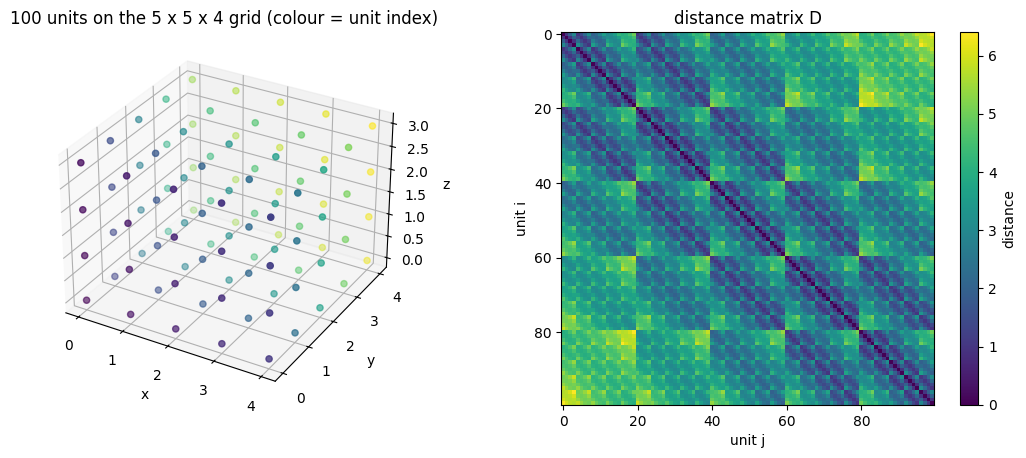

penalty on an orthogonal W:  seRNN 12.191  |  L1 5.289


In [7]:
# seRNN regulariser [DEMO cell 21]
regu_sernn = SE1_sWc(se1=GAMMA_SERNN)
# L1 regulariser [CAPSULE recording_decoding_demo, cell 8]
regu_l1 = tf.keras.regularizers.L1(GAMMA_L1)

# Unit positions: unit k sits at (x, y, z) = coords[k]
coords = np.stack(regu_sernn.coordinates, axis=1)       # (100, 3)
D = regu_sernn.distance_matrix                         # (100, 100), D[i, j] = Euclidean distance between units i and j
print("coords", coords.shape, "| first units:", coords[:5].tolist())
print("D", D.shape, "| symmetric:", np.allclose(D, D.T), "| diagonal = 0:", np.all(np.diag(D) == 0),
      f"| off-diagonal min {D[D > 0].min():.2f}, max {D.max():.2f}")

fig = plt.figure(figsize=(11, 4.5))
# Left: the grid. (The demo's visualise_neuron_structure draws an empty figure with recent matplotlib.)
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=np.arange(100), cmap='viridis')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('100 units on the 5 x 5 x 4 grid (colour = unit index)')
# Right: the distance matrix
ax = fig.add_subplot(1, 2, 2)
im = ax.imshow(D, cmap='viridis')
fig.colorbar(im, ax=ax, label='distance')
ax.set_xlabel('unit j'); ax.set_ylabel('unit i'); ax.set_title('distance matrix D')
plt.tight_layout(); plt.show()

# Sanity check: both penalties on a matrix like the network's initial W_rec (orthogonal)
W0 = tf.keras.initializers.Orthogonal(seed=0)((N_UNITS, N_UNITS))
print(f"penalty on an orthogonal W:  seRNN {float(regu_sernn(W0)):.3f}  |  L1 {float(regu_l1(W0)):.3f}")

#### Block 5 — Model

Same network as the demo [DEMO cells 21 + 23], for both groups. Only the regulariser on `W_rec` changes.

- `GaussianNoise(0.05)`: noise on the inputs, active during training only.
- `SimpleRNN(100)`: ReLU, orthogonal init of `W_rec`. Update rule: h_t = ReLU(W_in x_t + W_rec h_{t-1} + b).
- `Dense(4, softmax)`: one output per direction, read once at the last time step.
- Adam (default parameters, lr 0.001), cross-entropy loss.

Keras stores the recurrent weights as `recurrent_kernel[pre, post]`. We use `W_rec = recurrent_kernel.T`, so that `W_rec[i, j]` = weight from unit j to unit i.

In [8]:
# [DEMO cells 21 + 23] the demo's model, wrapped in a function so both groups use the same code
def make_model(recurrent_regularizer):
    model = tf.keras.models.Sequential([
        tf.keras.layers.GaussianNoise(stddev=INPUT_NOISE_STD),
        tf.keras.layers.SimpleRNN(N_UNITS, activation='relu', recurrent_initializer='orthogonal',
                                  return_sequences=False, recurrent_regularizer=recurrent_regularizer),
        tf.keras.layers.Dense(N_OUT, activation='softmax')
    ])
    model.build(input_shape=example_data[0].shape)
    model.compile(optimizer=tf.keras.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

tf.keras.backend.clear_session()
model_sernn = make_model(regu_sernn)
model_l1 = make_model(regu_l1)
model_sernn.summary()

# Weights of the RNN layer (layer 1): input weights, recurrent kernel, bias
W_in, K, b = model_sernn.layers[1].get_weights()
W_rec = K.T
print("W_in", W_in.shape, "| recurrent_kernel", K.shape, "| b", b.shape)
print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
print("regulariser on the RNN layer:  seRNN", type(model_sernn.layers[1].recurrent_regularizer).__name__,
      "| L1", type(model_l1.layers[1].recurrent_regularizer).__name__)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (128, 50, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (128, 100)             │        10,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (128, 4)               │           404 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,304 (44.16 KB)

 Trainable params: 11,304 (44.16 KB)

 Non-trainable params: 0 (0.00 B)

W_in (8, 100) | recurrent_kernel (100, 100) | b (100,)
W_rec orthogonal at init: True
regulariser on the RNN layer:  seRNN SE1_sWc | L1 L1


/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_20663/3188947228.py:22: RuntimeWarning: divide by zero encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_20663/3188947228.py:22: RuntimeWarning: overflow encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_20663/3188947228.py:22: RuntimeWarning: invalid value encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))


#### Block 6 — Train the 10 + 10 networks

One network per seed of `SEEDS` (block 2): 10 seRNN, 10 L1. Before each model, all seeds (python, numpy, TF) are reset to that seed.

- Accuracy = fraction of the 16 problems answered correctly, each problem once, without input noise. > 0.9 means at least 15/16. Every network must pass (checked).
- The seed lists come from first_draft Phase B (first 10 passing seeds per group). The weights obtained here are identical to Phase B, so its compression results can be reproduced.
- Networks are saved to `outputs/networks/` (W_in, W_rec, b, W_out, b_out, accuracy curves), so later blocks never retrain.

Time: about 3.5 s per network, ~1 min 10 in total.

In [9]:
# The 16 problems, each once, without noise: the set used for the > 90 % criterion
X16 = np.stack(gen.mazesdf['Problem_Vec']).reshape(16, GOAL_STEPS + DELAY_STEPS + CHOICE_STEPS, 8).astype('float32')
Y16 = np.stack(gen.mazesdf['Step_Encoded']).astype('float32')

def accuracy16(model):
    """Fraction of the 16 problems answered correctly (GaussianNoise is off outside training)."""
    return float(np.mean(model.predict(X16, verbose=0).argmax(1) == Y16.argmax(1)))

def train(seed, regu):
    """Train one network from a seed."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)          # python, numpy and TF seeds
    model = make_model(regu)
    history = model.fit(tfdf, epochs=EPOCHS, validation_data=tfdf_test, verbose=0)
    return model, history.history

def get_weights(model):
    W_in, K, b = model.layers[1].get_weights()
    W_out, b_out = model.layers[2].get_weights()
    return dict(W_in=W_in, W_rec=K.T, b=b, W_out=W_out, b_out=b_out)   # W_rec = recurrent_kernel.T (block 5)

os.makedirs(f"{OUT_DIR}/networks", exist_ok=True)
REGULARISERS = {'seRNN': regu_sernn, 'L1': regu_l1}
results = []
for group, regu in REGULARISERS.items():
    for seed in SEEDS[group]:
        model, hist = train(seed, regu)
        acc = accuracy16(model)
        np.savez(f"{OUT_DIR}/networks/{group}_seed{seed}.npz", **get_weights(model), acc16=acc,
                 accuracy=hist['accuracy'], val_accuracy=hist['val_accuracy'], loss=hist['loss'])
        results.append(dict(group=group, seed=seed, acc16=acc))
        print(f"{group:5s} seed {seed:2d}   accuracy {acc:.4f} ({round(acc * 16)}/16)")

results = pd.DataFrame(results)
results.to_csv(f"{OUT_DIR}/networks/accuracy.csv", index=False)
assert (results.acc16 > ACC_MIN).all(), results[results.acc16 <= ACC_MIN]
print(f"\nall {len(results)} networks pass {ACC_MIN}")

/Users/leandreramos/Desktop/work/Personal/Research/NeuroAI/MorphoAI/Spatial_Compressibility/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1794407810.610548 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is n

seRNN seed  2   accuracy 1.0000 (16/16)
seRNN seed  5   accuracy 0.9375 (15/16)


E0000 00:00:1794407817.971297 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed  7   accuracy 1.0000 (16/16)
seRNN seed 10   accuracy 1.0000 (16/16)


E0000 00:00:1794407825.504150 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed 11   accuracy 0.9375 (15/16)
seRNN seed 13   accuracy 0.9375 (15/16)


... (10 outputs left out)

E0000 00:00:1794407866.874700 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed 12   accuracy 0.9375 (15/16)
L1    seed 13   accuracy 0.9375 (15/16)


E0000 00:00:1794407873.366087 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed 18   accuracy 0.9375 (15/16)
L1    seed 19   accuracy 0.9375 (15/16)

all 20 networks pass 0.9


#### Block 7 — The 20 networks: what we keep for the bottleneck

Last seRNN block. Loads the networks saved by block 6 (no retraining) and keeps, for each one:

- `W_rec` (100 × 100): the matrix G will have to regenerate. The other weights (W_in, b, W_out, b_out) stay fixed.
- `acc16`: accuracy of the intact network on the 16 problems = the **baseline** that T0 is compared to.
- `ΣW = Σ |w_ij|`: the paper's sparsity measure (Fig. 2b, Fig. 6). ≈ 800 at init (orthogonal W_rec). Reported as a control, not a selection criterion.

Also needed for G, from block 4: the unit positions `coords` (for the positional labels).

Figures: test accuracy per epoch for each network; |W_rec| of one network per group (units in the demo order: blocks of 20 = one y layer).

acc16                        sumW                         
        mean    std    min  max     mean     std     min      max
group                                                            
seRNN  0.969  0.033  0.938  1.0  134.201  33.473  83.759  187.879
L1     0.950  0.026  0.938  1.0  135.668  43.784  83.100  188.777

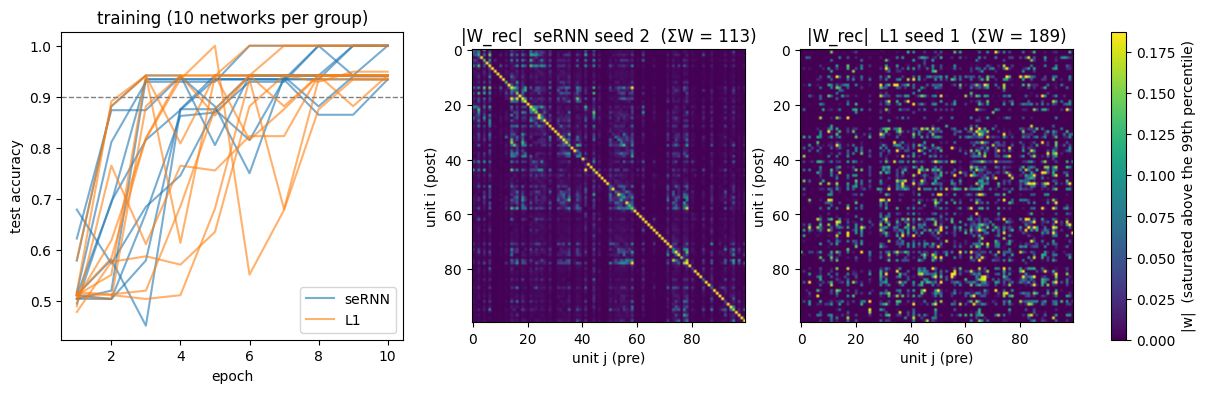

In [10]:
# Load the networks saved by block 6
NETS = {(group, seed): dict(np.load(f"{OUT_DIR}/networks/{group}_seed{seed}.npz"))
        for group in SEEDS for seed in SEEDS[group]}

networks = pd.DataFrame([dict(group=group, seed=seed, acc16=float(net['acc16']), sumW=float(np.abs(net['W_rec']).sum()))
                         for (group, seed), net in NETS.items()])
display(networks.groupby('group', sort=False)[['acc16', 'sumW']].agg(['mean', 'std', 'min', 'max']).round(3))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# Left: accuracy on the test set after each epoch (one line per network)
for group, color in [('seRNN', 'tab:blue'), ('L1', 'tab:orange')]:
    for seed in SEEDS[group]:
        axs[0].plot(range(1, EPOCHS + 1), NETS[(group, seed)]['val_accuracy'], color=color, alpha=0.6,
                    label=group if seed == SEEDS[group][0] else None)
axs[0].axhline(ACC_MIN, color='grey', ls='--', lw=1)
axs[0].set_xlabel('epoch'); axs[0].set_ylabel('test accuracy'); axs[0].set_title('training (10 networks per group)')
axs[0].legend()
# Middle and right: |W_rec| of the first network of each group, same colour scale
mats = {group: np.abs(NETS[(group, SEEDS[group][0])]['W_rec']) for group in SEEDS}
vmax = max(np.quantile(m, 0.99) for m in mats.values())
for ax, (group, m) in zip(axs[1:], mats.items()):
    im = ax.imshow(m, cmap='viridis', vmin=0, vmax=vmax)
    ax.set_title(f"|W_rec|  {group} seed {SEEDS[group][0]}  (ΣW = {m.sum():.0f})")
    ax.set_xlabel('unit j (pre)'); ax.set_ylabel('unit i (post)')
fig.colorbar(im, ax=axs[1:].tolist(), label='|w|  (saturated above the 99th percentile)')
plt.show()

#### Block 7b — Structure: modularity and small-worldness of the 20 networks

Check that the seRNNs are really spatially constrained networks, as in the paper (Fig. 3): **more modular and more small-world than L1**.

Method [PAPER Methods, 'Topological analysis'] [CAPSULE `computing_topology.m`]:
1. **Modularity Q** (resolution 1), on the **full weighted graph |W_rec|, diagonal (self-connections) included**, exactly as the capsule: `modularity_und(abs(W))`. Q measures how well the network splits into groups with strong connections inside and weak ones between. 0 = no better than random; real cortical networks ≈ 0.3–0.6. Algorithm: BCT `modularity_und` (Newman's spectral method, deterministic, no seed), the Python port in bctpy. The graph is made undirected with (|W| + |W|ᵀ) / 2.
2. **Small-worldness σ** on the binary graph: keep the top 10 % of |W_rec| (diagonal excluded), set them to 1 and the rest to 0, undirected (i–j connected if either direction is kept). σ = (C / C_rand) / (L / L_rand). C = clustering (are my neighbours connected to each other?), L = typical path length between nodes (here 1 / global efficiency, as in [DEMO cell 33], robust to isolated nodes). C_rand, L_rand = mean over 1000 random graphs with the same number of nodes and edges. σ > 1 = small-world.

Paper reference, Fig. 3 at epoch 9 (read off the figure, 8-problem task, whole γ spectrum): Q ≈ 0.35 (seRNN) vs ≈ 0.15 (L1); σ ≈ 2.4 (seRNN) vs ≈ 2.0 (L1).

Q        n_modules         sigma        C_over_Crand         \
        mean    std      mean    std   mean    std         mean    std   
group                                                                    
seRNN  0.287  0.065      35.4  8.208  2.545  0.783         3.67  0.596   
L1     0.118  0.028       4.0  0.943  1.555  0.200         2.28  0.374   

      L_over_Lrand        
              mean   std  
group                     
seRNN        1.493  0.20  
L1           1.462  0.09

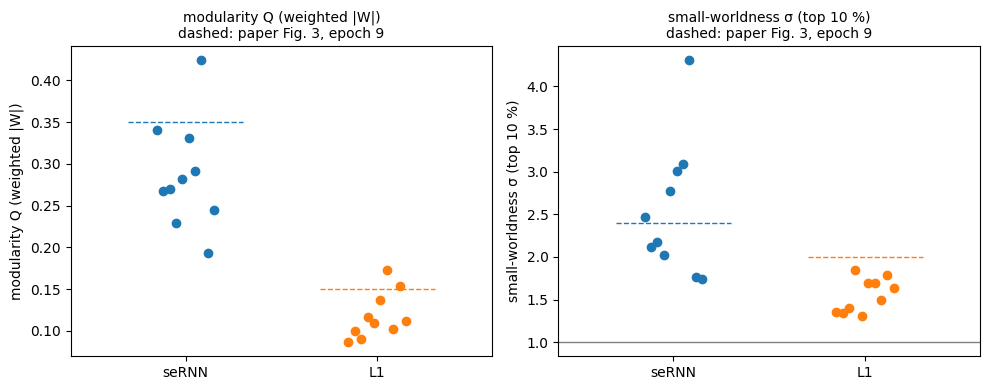

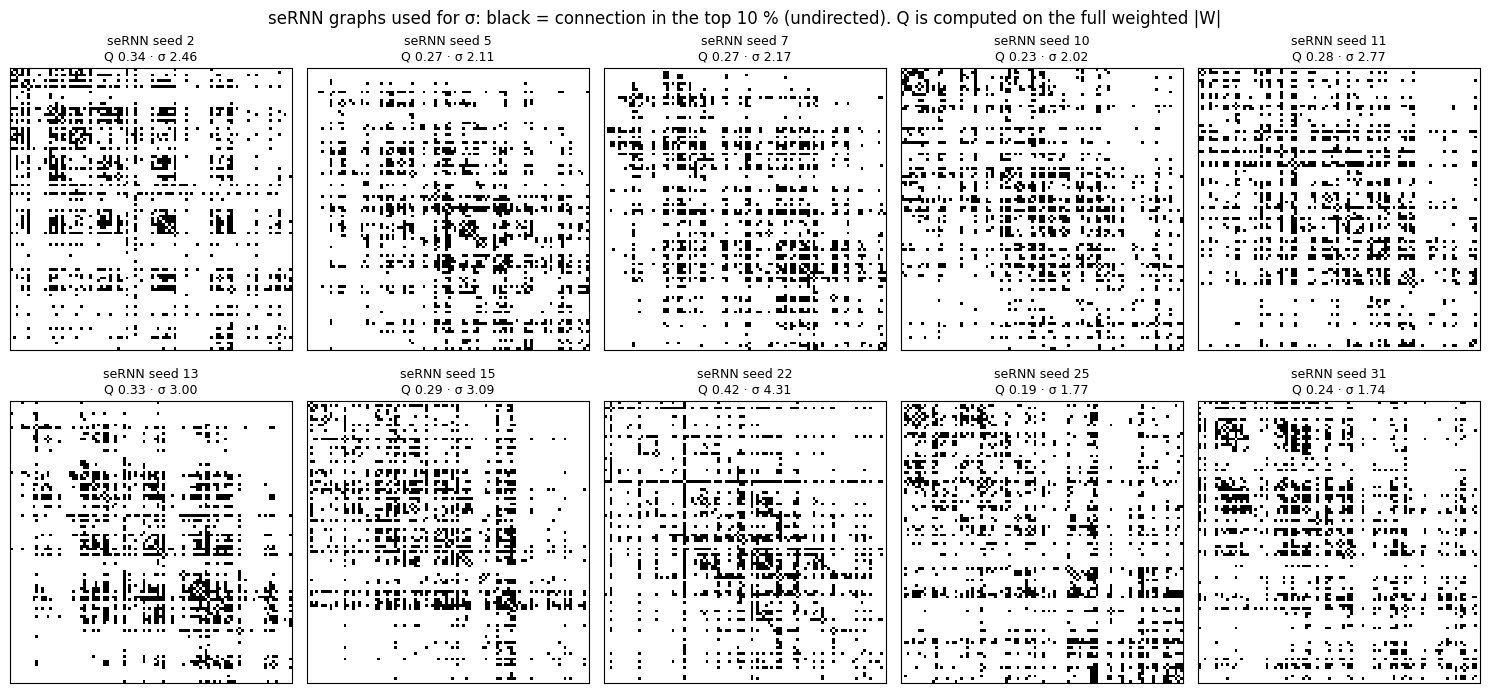

In [11]:
# Modularity = BCT modularity_und [CAPSULE computing_topology.m], via bctpy.
# bctpy 0.6.1 crashes with numpy 2 only in its last helper ls2ci (list of modules -> labels): replaced below.
def ls2ci(ls, zeroindexed=False):
    """List of modules -> community label of each node (same output as bctpy's ls2ci)."""
    ci = np.zeros(sum(len(module) for module in ls), dtype=int)
    for i, module in enumerate(ls):
        ci[np.array(module, dtype=int)] = i + (0 if zeroindexed else 1)
    return ci
bct.algorithms.modularity.ls2ci = ls2ci

def modularity(W):
    """Q on the full weighted |W|, diagonal included [CAPSULE: modularity_und(abs(W))], made undirected."""
    A = np.abs(W)
    ci, Q = bct.modularity_und((A + A.T) / 2, gamma=MOD_GAMMA)
    return ci, Q


def binarise(W):
    """For small-worldness: top TOP_PROP of |W| -> 1, rest -> 0, diagonal removed [PAPER] (bct.threshold_proportional = [CAPSULE]).
    Undirected: i-j connected if either direction is kept."""
    A = bct.threshold_proportional(np.abs(W), TOP_PROP)
    return ((A + A.T) > 0).astype(float)

def small_worldness(A):
    """sigma = (C / C_rand) / (L / L_rand), L = 1 / global efficiency [DEMO cell 33].
    Null: N_NULL random undirected graphs with the same number of nodes and edges [PAPER] [CAPSULE makerandCIJ_und]."""
    C, E = np.mean(bct.clustering_coef_bu(A)), bct.efficiency_bin(A)
    n_edges = int(A.sum() / 2)
    rng = np.random.RandomState(NULL_SEED)
    C_rand, E_rand = [], []
    for _ in range(N_NULL):
        R = bct.makerandCIJ_und(len(A), n_edges, seed=rng)
        R = R + R.T   # bctpy returns only the upper triangle; MATLAB BCT returns CIJ + CIJ' (symmetric)
        C_rand.append(np.mean(bct.clustering_coef_bu(R)))
        E_rand.append(bct.efficiency_bin(R))
    C_rand, E_rand = np.mean(C_rand), np.mean(E_rand)
    return (C / C_rand) * (E / E_rand), C / C_rand, E_rand / E      # sigma, C/C_rand, L/L_rand

rows = []
for (group, seed), net in NETS.items():
    ci, Q = modularity(net['W_rec'])
    A = binarise(net['W_rec'])
    sigma, c_ratio, l_ratio = small_worldness(A)
    rows.append(dict(group=group, seed=seed, Q=Q, n_modules=len(np.unique(ci)), sigma=sigma,
                     C_over_Crand=c_ratio, L_over_Lrand=l_ratio))
structure = pd.DataFrame(rows)
structure.to_csv(f"{OUT_DIR}/networks/structure.csv", index=False)
display(structure.groupby('group', sort=False)[['Q', 'n_modules', 'sigma', 'C_over_Crand', 'L_over_Lrand']]
        .agg(['mean', 'std']).round(3))

# One dot per network; paper Fig. 3 values (epoch 9) as dashed lines
COLORS = {'seRNN': 'tab:blue', 'L1': 'tab:orange'}
PAPER = {'Q': {'seRNN': 0.35, 'L1': 0.15}, 'sigma': {'seRNN': 2.4, 'L1': 2.0}}
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, label in [(axs[0], 'Q', 'modularity Q (weighted |W|)'), (axs[1], 'sigma', 'small-worldness σ (top 10 %)')]:
    for k, group in enumerate(SEEDS):
        v = structure[structure.group == group][metric]
        ax.scatter(np.full(len(v), k) + np.linspace(-0.15, 0.15, len(v)), v, color=COLORS[group])
        ax.hlines(PAPER[metric][group], k - 0.3, k + 0.3, color=COLORS[group], ls='--', lw=1)
    if metric == 'sigma':
        ax.axhline(1, color='grey', lw=1)
    ax.set_xticks([0, 1]); ax.set_xticklabels(list(SEEDS)); ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel(label); ax.set_title(f"{label}\ndashed: paper Fig. 3, epoch 9", fontsize=10)
plt.tight_layout(); plt.show()

# The 10 seRNN graphs used for σ (top 10 % binarised), units in the demo order (blocks of 20 = one y layer of the grid)
fig, axs = plt.subplots(2, 5, figsize=(15, 7.2))
for ax, seed in zip(axs.ravel(), SEEDS['seRNN']):
    ax.imshow(binarise(NETS[('seRNN', seed)]['W_rec']), cmap='Greys', interpolation='nearest')
    q = structure[(structure.group == 'seRNN') & (structure.seed == seed)].iloc[0]
    ax.set_title(f"seRNN seed {seed}\nQ {q.Q:.2f} · σ {q.sigma:.2f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('seRNN graphs used for σ: black = connection in the top 10 % (undirected). Q is computed on the full weighted |W|'); plt.tight_layout(h_pad=2.5); plt.show()

> **⚠️ Finding (flag for the next steps): the seRNN modularity is mostly the diagonal.**
>
> - Q is computed as in the paper: on |W|, self-connections (the diagonal) included.
> - Across the 10 seRNNs, Q follows the share of |W| sitting on the diagonal almost perfectly (r = 0.98). Seed 22 puts 37 % of its weight on self-connections → Q = 0.42. Seed 25 puts 13 % → Q = 0.19.
> - Without the diagonal, seRNN and L1 are almost equally modular (Q ≈ 0.12 vs 0.11).
> - The paper never mentions the diagonal (Methods, 'Topological analysis').
> - It is not a pure artefact: σ, computed *without* the diagonal, also follows it (r = 0.94). A strong diagonal means a network that cut most of its unit-to-unit connections.
> - **Why it matters for the bottleneck:** a diagonal weight is the pair (i, i), so G sees the same label twice. G can spot those pairs with positional **and** random labels. Part of the seRNN "structure" is therefore easy for G whatever the labels: keep this in mind when reading the seRNN-positional vs seRNN-random comparison.

seRNN  diagonal share 0.216  |  r(diag share, Q) = 0.98  |  r(diag share, σ) = 0.94
L1     diagonal share 0.024  |  r(diag share, Q) = 0.79  |  r(diag share, σ) = 0.82


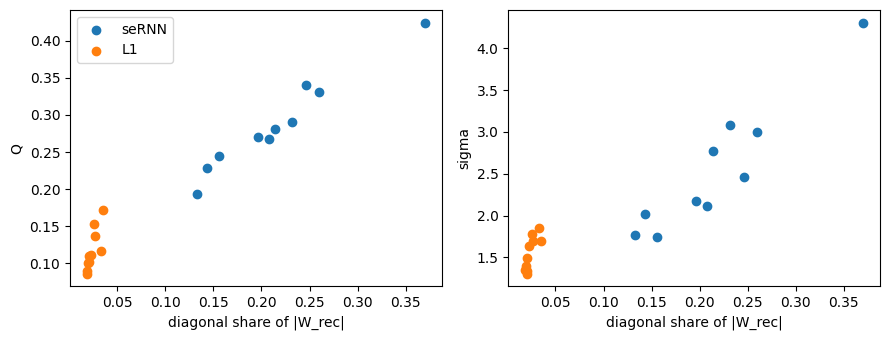

In [12]:
# Where the r of the note comes from
# diagonal share = sum |w_ii| / sum |w_ij|: fraction of the network's total weight sitting on self-connections
structure['diag_share'] = [np.trace(np.abs(NETS[(g, s)]['W_rec'])) / np.abs(NETS[(g, s)]['W_rec']).sum()
                           for g, s in zip(structure.group, structure.seed)]
# r = Pearson correlation: +1 = the points lie exactly on a rising line, 0 = no linear link
for group in SEEDS:
    x = structure[structure.group == group]
    print(f"{group:5s}  diagonal share {x.diag_share.mean():.3f}  |  r(diag share, Q) = {np.corrcoef(x.diag_share, x.Q)[0, 1]:.2f}"
          f"  |  r(diag share, σ) = {np.corrcoef(x.diag_share, x.sigma)[0, 1]:.2f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, metric in zip(axs, ['Q', 'sigma']):
    for group in SEEDS:
        x = structure[structure.group == group]
        ax.scatter(x.diag_share, x[metric], color=COLORS[group], label=group)
    ax.set_xlabel('diagonal share of |W_rec|'); ax.set_ylabel(metric)
axs[0].legend(); plt.tight_layout(); plt.show()

#### Block 8 — Bottleneck: hyperparameters

From here on, each trained network P is compressed by a **g-network G** (Zador's genomic bottleneck).

- Each of the 100 units gets an 8-bit **label**:
  - **positional**: its (x, y, z) position on the grid, in Gray code (two neighbouring units differ by one bit);
  - **random**: an arbitrary code, unrelated to position (control).
- G is a small MLP. Input: the labels of the two units, concat(label_i, label_j) = 16 bits. Output: the weight W_rec[i, j].
- G is trained once (MSE) on all 10,000 weights of W_rec. Then W_rec is rebuilt from G, put back into P, and P is tested with no retraining (**T0**).
- **Compression ratio** = 10,000 (weights of W_rec) / number of parameters of G. Ratio 1 = G has as many parameters as W_rec, so in principle it could memorise it. Ratio 0.5 = G is twice as big (no compression: checks that G can fit W_rec at all).

In [19]:
# Labels [PLAN step 1]
BITS_X, BITS_Y, BITS_Z = 3, 3, 2      # positional label = Gray code of (x, y, z): x, y in 0..4 -> 3 bits, z in 0..3 -> 2 bits
LABEL_BITS = BITS_X + BITS_Y + BITS_Z  # 8 bits per unit -> G input = concat(label_i, label_j) = 16 bits
RANDOM_LABEL_SEED = 0                 # random labels: 100 distinct 8-bit codes drawn from the 256

# g-network G [ZADOR], single pass: fit all N_UNITS^2 weights of W_rec once (MSE), no Zador loop for now
G_WIDTHS = [18, 27, 42, 62, 91]       # G = 16 -> 2w -> w -> 1, the shape of the plan's 16 -> 20 -> 10 -> 1
G_ACTIVATION = 'relu'                 # hidden layers; output linear (a real-valued weight)
G_EPOCHS = 4000
G_BATCH_SIZE = 256
G_LR = 1e-3                           # Adam, cosine decay to 0 over training
G_SEED = 0                            # same G initialisation for every P, label type and size
N_JOBS = 10                            # G's trained at the same time (independent processes); results identical to one at a time

# Compression ratio of each G size
N_COMPRESSED = N_UNITS * N_UNITS      # only W_rec is compressed: 10,000 weights

def g_n_params(w):
    sizes = (2 * LABEL_BITS, 2 * w, w, 1)
    return sum(a * b + b for a, b in zip(sizes[:-1], sizes[1:]))

g_sizes = pd.DataFrame([dict(w=w, architecture=f"{2 * LABEL_BITS} -> {2 * w} -> {w} -> 1", params=g_n_params(w),
                             ratio=round(N_COMPRESSED / g_n_params(w), 2)) for w in G_WIDTHS])
display(g_sizes.set_index('w'))

,architecture,params,ratio
w,,,
18,16 -> 36 -> 18 -> 1,1297,7.71
27,16 -> 54 -> 27 -> 1,2431,4.11
42,16 -> 84 -> 42 -> 1,5041,1.98
62,16 -> 124 -> 62 -> 1,9921,1.01
91,16 -> 182 -> 91 -> 1,19839,0.50


#### Block 9 — Labels and G: build, train one, check

1. **Labels** (one 8-bit code per unit):
   - positional = Gray code of the unit's (x, y, z) on the grid (3 + 3 + 2 bits): two neighbouring units differ by 1 bit;
   - random = 100 distinct 8-bit codes drawn at random (seed `RANDOM_LABEL_SEED`), unrelated to position. The same random labels are used for every network.
2. **G's data**: one row per weight, 10,000 rows. Input = [label_i, label_j], target = W_rec[i, j] (weight from unit j to unit i).
3. **Train G**: MSE, Adam with cosine decay, `G_EPOCHS` epochs, same seed for every G.
4. **T0**: rebuild W_rec with G and put it into a copy of the network (W_in, W_out and biases unchanged). Then measure its accuracy on the 16 problems, with no retraining.
5. **Check**: putting the network's own W_rec back must give exactly its accuracy (all 20 networks).
6. **Example**: the first seRNN, positional labels, ratio 1.

Each trained G is saved to `outputs/bottleneck/G/` (the W_rec it rebuilds + its loss curve), so block 10 does not retrain it. If a block-8 value changes, the saved G no longer matches and is retrained.

unit  (x, y, z)    positional  random
   0  (0, 0, 0)   00000000    01000001
   1  (0, 0, 1)   00000001    00000100
   2  (0, 0, 2)   00000011    11110011
  20  (0, 1, 0)   00000100    10111111
  99  (4, 4, 3)   11011010    01001111


E0000 00:00:1794479873.938255 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



check OK: own W_rec -> same accuracy, all 20 networks


E0000 00:00:1794479983.140527 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed 2, positional, w = 62 (ratio 1.01):  MSE / Var(W_rec) = 0.009  |  accuracy of P 1.000  ->  T0 0.750


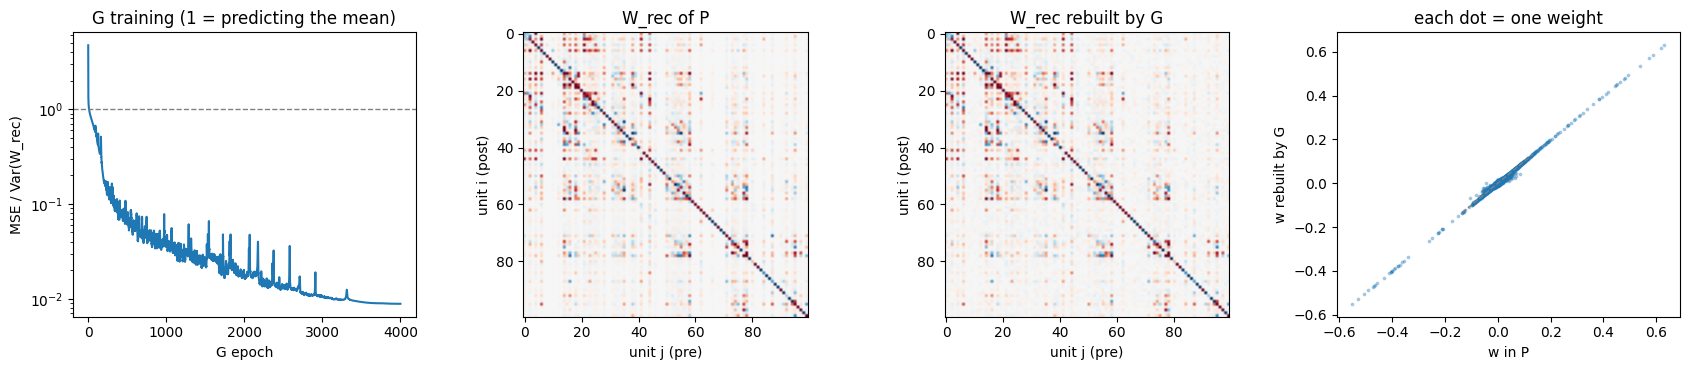

In [18]:
# 1. Labels
def gray_bits(value, n_bits):
    """Gray code of an integer, as n_bits bits (most significant first)."""
    g = int(value) ^ (int(value) >> 1)
    return [(g >> (n_bits - 1 - b)) & 1 for b in range(n_bits)]

labels_pos = np.array([gray_bits(x, BITS_X) + gray_bits(y, BITS_Y) + gray_bits(z, BITS_Z) for x, y, z in coords],
                      dtype='float32')                                                # coords from block 4b
codes = np.random.default_rng(RANDOM_LABEL_SEED).choice(2 ** LABEL_BITS, N_UNITS, replace=False)
labels_rand = np.array([[(c >> (LABEL_BITS - 1 - b)) & 1 for b in range(LABEL_BITS)] for c in codes], dtype='float32')
LABELS = {'positional': labels_pos, 'random': labels_rand}

for name, lab in LABELS.items():
    assert lab.shape == (N_UNITS, LABEL_BITS) and len(np.unique(lab, axis=0)) == N_UNITS   # one distinct label per unit
hamming = np.abs(labels_pos[:, None] - labels_pos[None]).sum(-1)    # number of differing bits between two labels
assert np.all(hamming[D == 1] == 1)                                  # grid neighbours differ by exactly 1 bit
print("unit  (x, y, z)    positional  random")
for k in [0, 1, 2, 20, 99]:
    print(f"{k:4d}  {tuple(int(v) for v in coords[k])}   {''.join(map(str, labels_pos[k].astype(int)))}    "
          f"{''.join(map(str, labels_rand[k].astype(int)))}")

# 2. G's data: row r = i * N_UNITS + j  <->  input [label_i, label_j]  <->  target W_rec[i, j]
def pair_inputs(labels):
    return np.concatenate([np.repeat(labels, N_UNITS, axis=0), np.tile(labels, (N_UNITS, 1))], axis=1)

_X = pair_inputs(labels_pos)
i, j = 3, 57
assert np.array_equal(_X[i * N_UNITS + j], np.concatenate([labels_pos[i], labels_pos[j]]))
assert NETS[('seRNN', SEEDS['seRNN'][0])]['W_rec'].reshape(-1)[i * N_UNITS + j] == NETS[('seRNN', SEEDS['seRNN'][0])]['W_rec'][i, j]

# 3. G and its training
def make_G(w):
    """G = 16 -> 2w -> w -> 1 (block 8)."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(G_SEED)
    G = tf.keras.Sequential([tf.keras.Input(shape=(2 * LABEL_BITS,)),
                             tf.keras.layers.Dense(2 * w, activation=G_ACTIVATION),
                             tf.keras.layers.Dense(w, activation=G_ACTIVATION),
                             tf.keras.layers.Dense(1)])
    n_steps = G_EPOCHS * int(np.ceil(N_COMPRESSED / G_BATCH_SIZE))
    G.compile(optimizer=tf.keras.optimizers.Adam(tf.keras.optimizers.schedules.CosineDecay(G_LR, n_steps)), loss='mse')
    assert G.count_params() == g_n_params(w)
    return G

def train_G(w, labels, W_rec):
    """Fit G on the N_UNITS^2 weights of W_rec. Returns the W_rec rebuilt by G and the loss after each epoch."""
    X, y = pair_inputs(labels), W_rec.reshape(-1, 1)
    G = make_G(w)
    history = G.fit(X, y, batch_size=G_BATCH_SIZE, epochs=G_EPOCHS, shuffle=True, verbose=0)
    W_hat = G.predict(X, batch_size=N_COMPRESSED, verbose=0).reshape(N_UNITS, N_UNITS)
    return W_hat, np.array(history.history['loss'])

G_SETTINGS = str([G_ACTIVATION, G_EPOCHS, G_BATCH_SIZE, G_LR, G_SEED, RANDOM_LABEL_SEED])   # what a saved G depends on

def run_G(group, seed, label_type, w):
    """Train G for one (network, label type, size), or reload it if already saved with the same settings."""
    path = f"{OUT_DIR}/bottleneck/G/{group}_seed{seed}_{label_type}_w{w}.npz"
    if os.path.exists(path):
        saved = np.load(path)
        if str(saved['settings']) == G_SETTINGS:
            return saved['W_hat'], saved['loss']
    W_hat, loss = train_G(w, LABELS[label_type], NETS[(group, seed)]['W_rec'])
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.savez(path, W_hat=W_hat, loss=loss, settings=G_SETTINGS)
    return W_hat, loss

# 4. T0: accuracy of the network with W_rec replaced, no retraining
def T0(net, W_rec_new):
    model = make_model(None)
    model.layers[1].set_weights([net['W_in'], W_rec_new.T, net['b']])   # Keras stores W_rec transposed (block 5)
    model.layers[2].set_weights([net['W_out'], net['b_out']])
    return accuracy16(model)

# 5. Check: the network's own W_rec gives back exactly its accuracy
for key, net in NETS.items():
    assert T0(net, net['W_rec']) == float(net['acc16']), key
print("\ncheck OK: own W_rec -> same accuracy, all 20 networks")

# 6. Example: first seRNN, positional labels, ratio 1 (w = 62)
group, seed, w = 'seRNN', SEEDS['seRNN'][0], 62
net = NETS[(group, seed)]
W_hat, loss = run_G(group, seed, 'positional', w)
var_W = np.var(net['W_rec'])
print(f"{group} seed {seed}, positional, w = {w} (ratio {N_COMPRESSED / g_n_params(w):.2f}):  "
      f"MSE / Var(W_rec) = {np.mean((W_hat - net['W_rec']) ** 2) / var_W:.3f}  |  "
      f"accuracy of P {float(net['acc16']):.3f}  ->  T0 {T0(net, W_hat):.3f}")

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
axs[0].plot(loss / var_W); axs[0].set_yscale('log'); axs[0].axhline(1, color='grey', ls='--', lw=1)
axs[0].set_xlabel('G epoch'); axs[0].set_ylabel('MSE / Var(W_rec)'); axs[0].set_title('G training (1 = predicting the mean)')
v = np.quantile(np.abs(net['W_rec']), 0.99)
for ax, M, title in [(axs[1], net['W_rec'], 'W_rec of P'), (axs[2], W_hat, 'W_rec rebuilt by G')]:
    ax.imshow(M, cmap='RdBu_r', vmin=-v, vmax=v); ax.set_title(title)
    ax.set_xlabel('unit j (pre)'); ax.set_ylabel('unit i (post)')
axs[3].scatter(net['W_rec'].ravel(), W_hat.ravel(), s=3, alpha=0.3)
axs[3].plot([-v, v], [-v, v], color='grey', ls='--', lw=1)
axs[3].set_xlabel('w in P'); axs[3].set_ylabel('w rebuilt by G'); axs[3].set_title('each dot = one weight')
plt.tight_layout(); plt.show()

#### Block 10 — Compress all 20 networks: the T0 table

For each network (20), label type (2) and G size (5): train G, rebuild W_rec, measure T0. That is 200 G's.

Columns of the table:
- `mse_rel` = MSE / Var(W_rec): 1 = no better than predicting the mean weight, 0 = perfect copy.
- `T0` = accuracy of the network with the rebuilt W_rec, no retraining.
- `acc_P` = accuracy of the original network (ceiling).
- `floor` = T0 when every weight is replaced by the mean weight, i.e. what a G that learned nothing gives.
- `T0_norm` = (T0 − floor) / (acc_P − floor), per network: 1 = as good as the original network, 0 = no better than the floor. It puts every network on the same scale, whatever its own accuracy and floor.

The G's are trained `N_JOBS` at a time (block 8), in separate processes: same results as one at a time, several times faster. Results go to `outputs/bottleneck/results.csv`. The cell can be stopped and run again: G's already saved are reloaded, not retrained.

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.


[Parallel(n_jobs=10)]: Done  52 tasks      | elapsed:    3.6s
[Parallel(n_jobs=10)]: Done 200 out of 200 | elapsed:    3.9s finished
E0000 00:00:1794484672.453840 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed  2 done
seRNN seed  5 done
seRNN seed  7 done
seRNN seed 10 done
seRNN seed 11 done
seRNN seed 13 done


E0000 00:00:1794484677.473006 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed 15 done
seRNN seed 22 done
seRNN seed 25 done
seRNN seed 31 done
L1    seed  1 done
L1    seed  7 done


E0000 00:00:1794484682.536323 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed  8 done
L1    seed  9 done
L1    seed 10 done
L1    seed 11 done
L1    seed 12 done
L1    seed 13 done


E0000 00:00:1794484687.541941 21979264 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed 18 done
L1    seed 19 done


mse_rel                                  T0                    \
group       seRNN                L1             seRNN                L1   
labels positional random positional random positional random positional   
ratio                                                                     
7.71        0.667  0.464      0.772  0.706      0.350  0.338      0.438   
4.11        0.187  0.261      0.460  0.432      0.369  0.369      0.494   
1.98        0.095  0.184      0.231  0.223      0.494  0.481      0.494   
1.01        0.016  0.028      0.044  0.040      0.762  0.775      0.831   
0.50        0.000  0.000      0.000  0.000      0.969  0.969      0.950   

                 T0_norm                               acc_P         \
group              seRNN                L1             seRNN          
labels random positional random positional random positional random   
ratio                                                                 
7.71    0.444      0.011 -0.017      0.039  0.047      0.969  0.969   
4.11    0.475      0.033  0.027      0.126  0.096      0.969  0.969   
1.98    0.525      0.215  0.191      0.120  0.186      0.969  0.969   
1.01    0.819      0.687  0.667      0.777  0.752      0.969  0.969   
0.50    0.950      1.000  1.000      1.000  1.000      0.969  0.969   

                              floor                           
group          L1             seRNN                L1         
labels positional random positional random positional random  
ratio                                                         
7.71         0.95   0.95      0.344  0.344      0.412  0.412  
4.11         0.95   0.95      0.344  0.344      0.412  0.412  
1.98         0.95   0.95      0.344  0.344      0.412  0.412  
1.01         0.95   0.95      0.344  0.344      0.412  0.412  
0.50         0.95   0.95      0.344  0.344      0.412  0.412

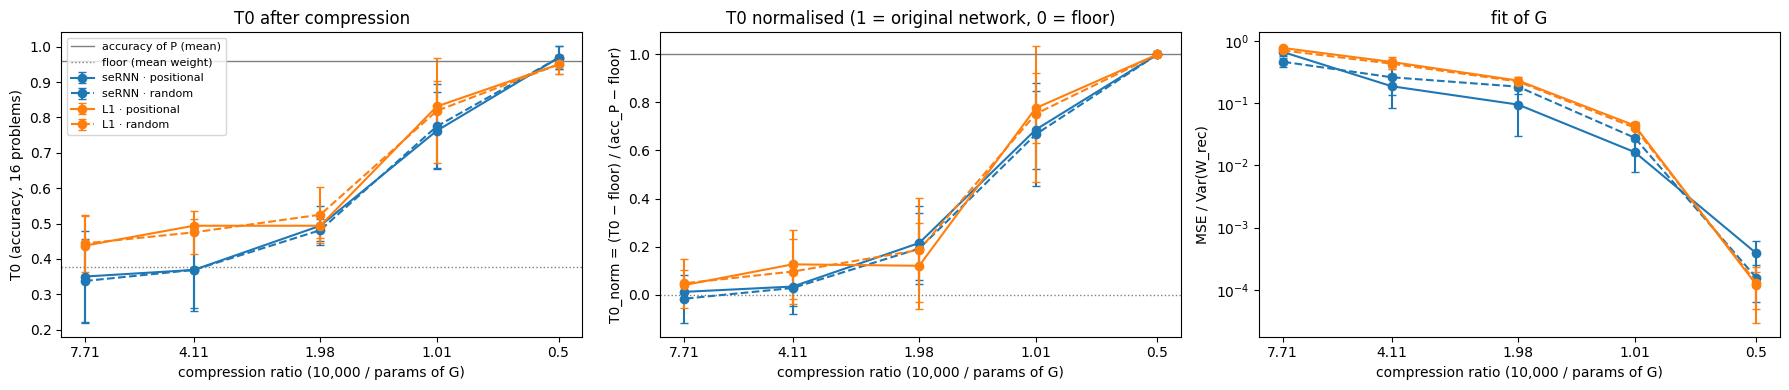

In [22]:
# 1. Train every G not saved yet, N_JOBS at a time (each G is independent; saved to outputs/bottleneck/G/)
from joblib import Parallel, delayed

def train_and_save(group, seed, label_type, w):
    tf.config.experimental.enable_op_determinism()   # each worker is a new process: same setting as block 2
    run_G(group, seed, label_type, w)

jobs = [(group, seed, label_type, w) for (group, seed) in NETS for label_type in LABELS for w in G_WIDTHS]
Parallel(n_jobs=N_JOBS, verbose=5)(delayed(train_and_save)(*job) for job in jobs)

# 2. Rebuild W_rec with each G (reloaded from disk) and measure T0
rows = []
for (group, seed), net in NETS.items():
    var_W = np.var(net['W_rec'])
    floor = T0(net, np.full_like(net['W_rec'], net['W_rec'].mean()))
    for label_type in LABELS:
        for w in G_WIDTHS:
            W_hat, loss = run_G(group, seed, label_type, w)
            rows.append(dict(group=group, seed=seed, labels=label_type, w=w, ratio=round(N_COMPRESSED / g_n_params(w), 2),
                             mse_rel=np.mean((W_hat - net['W_rec']) ** 2) / var_W, T0=T0(net, W_hat),
                             acc_P=float(net['acc16']), floor=floor))
    print(f"{group:5s} seed {seed:2d} done")

bottleneck = pd.DataFrame(rows)
bottleneck['T0_norm'] = (bottleneck.T0 - bottleneck.floor) / (bottleneck.acc_P - bottleneck.floor)
bottleneck.to_csv(f"{OUT_DIR}/bottleneck/results.csv", index=False)

# Mean over the 10 networks of each group, per compression ratio
summary = bottleneck.groupby(['ratio', 'group', 'labels'], sort=False)[['mse_rel', 'T0', 'T0_norm', 'acc_P', 'floor']].mean()
display(summary.unstack(['group', 'labels']).sort_index(ascending=False).round(3))

# T0 and fit vs compression ratio (mean ± std over the 10 networks)
STYLES = {'positional': '-', 'random': '--'}   # COLORS from block 7b
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for (group, label_type), x in bottleneck.groupby(['group', 'labels'], sort=False):
    m = x.groupby('ratio')[['T0', 'T0_norm', 'mse_rel']].agg(['mean', 'std'])
    for ax, metric in zip(axs, ['T0', 'T0_norm', 'mse_rel']):
        ax.errorbar(m.index, m[(metric, 'mean')], yerr=m[(metric, 'std')], color=COLORS[group], ls=STYLES[label_type],
                    marker='o', capsize=3, label=f"{group} · {label_type}")
axs[0].axhline(bottleneck.acc_P.mean(), color='grey', lw=1, label='accuracy of P (mean)')
axs[0].axhline(bottleneck.floor.mean(), color='grey', lw=1, ls=':', label='floor (mean weight)')
axs[0].set_ylabel('T0 (accuracy, 16 problems)'); axs[0].set_title('T0 after compression')
axs[1].axhline(1, color='grey', lw=1); axs[1].axhline(0, color='grey', lw=1, ls=':')
axs[1].set_ylabel('T0_norm = (T0 − floor) / (acc_P − floor)'); axs[1].set_title('T0 normalised (1 = original network, 0 = floor)')
axs[2].set_ylabel('MSE / Var(W_rec)'); axs[2].set_title('fit of G'); axs[2].set_yscale('log')
ratios = sorted(bottleneck.ratio.unique())
for ax in axs:
    ax.set_xscale('log'); ax.set_xticks(ratios, [str(r) for r in ratios]); ax.minorticks_off()
    ax.invert_xaxis()
    ax.set_xlabel('compression ratio (10,000 / params of G)')
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

#### Block 10b — Has G finished training? MSE curves at ratio 1.01

Ratio 1.01 is the size where G has about as many parameters as W_rec has weights: the size that decides between "compresses" and "copies". Here we look at how its training MSE moves epoch by epoch, for the 40 G's of that size (20 networks × 2 label types). Nothing is retrained: the MSE of every epoch is saved with each G (block 9).

Three panels:
1. MSE / Var(W_rec) per epoch (thin lines: one G; thick lines: median of the 10 networks of a condition).
2. How much the MSE still falls: median MSE of the last 250 epochs vs the 250 epochs before, in % (the median removes the noise and the spikes of the training loss). A real plateau = close to 0 % **while the learning rate is still high**.
3. The learning rate of Adam, which follows a cosine from `G_LR` to 0 (block 8). Near the end it is almost 0, so the curve flattens anyway: a flat end alone does not prove G has finished learning.

Note: the MSE logged during training is averaged over the epoch's batches, so its last value is close to, but not exactly, `mse_rel` of block 10.


,group,labels,MSE/Var @ 1000,MSE/Var @ 2000,MSE/Var @ 3000,MSE/Var @ 4000,"% decrease, last 100 ep","% decrease, epochs 1000 → end"
0,seRNN,positional,0.0860,0.0367,0.0287,0.0174,0.3363,75.9137
1,seRNN,random,0.1246,0.0547,0.0335,0.0267,0.4811,77.0907
2,L1,positional,0.1662,0.0827,0.0680,0.0450,0.4108,71.9235
3,L1,random,0.1432,0.0941,0.0569,0.0399,0.4615,73.2140


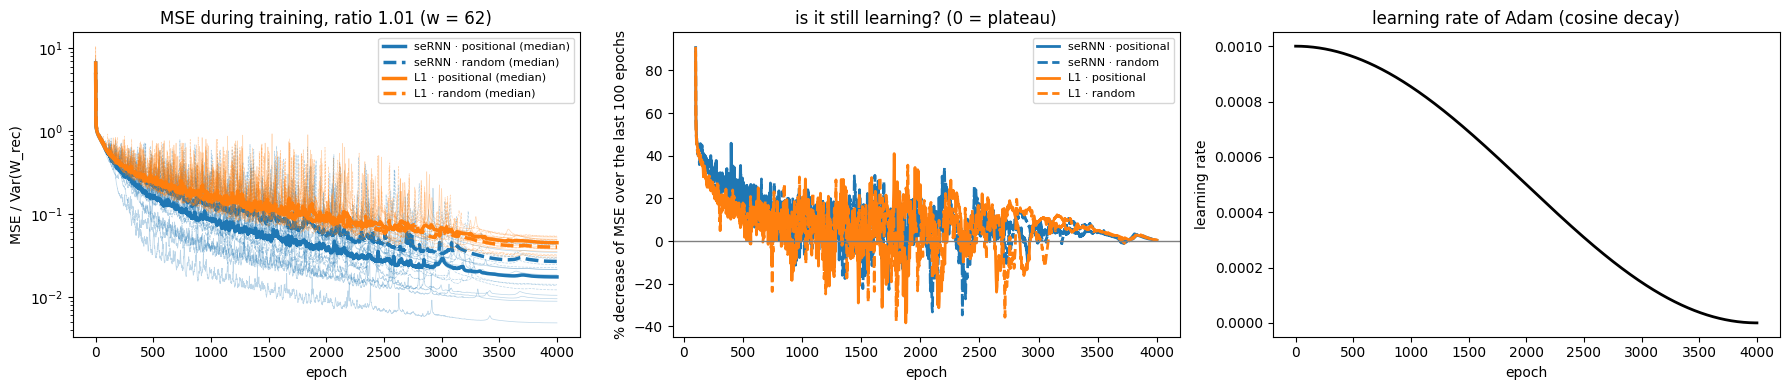

In [21]:
W_CURVE = 62        # G size inspected: ratio 1.01 (block 8)
WINDOW = 250        # epochs over which the % decrease is measured
CHECK_EPOCHS = [1000, 2000, 3000, G_EPOCHS]   # epochs shown in the table

# 1. Load the MSE curves of the saved G's (no retraining), divided by Var(W_rec)
curves = {}
for (group, seed), net in NETS.items():
    for label_type in LABELS:
        _, loss = run_G(group, seed, label_type, W_CURVE)
        curves[(group, seed, label_type)] = loss / np.var(net['W_rec'])
epochs = np.arange(1, G_EPOCHS + 1)

# 2. % decrease of the MSE: median of the last WINDOW epochs vs median of the WINDOW epochs before
#    (the median over WINDOW epochs removes the noise and the spikes of the training loss)
def pct_decrease(C):
    smooth = np.median(np.lib.stride_tricks.sliding_window_view(np.atleast_2d(C), WINDOW, axis=1), axis=-1)
    return 100 * (1 - smooth[:, WINDOW:] / smooth[:, :-WINDOW])

# 3. Learning rate at each epoch (same schedule as make_G, block 9)
steps_per_epoch = int(np.ceil(N_COMPRESSED / G_BATCH_SIZE))
schedule = keras.optimizers.schedules.CosineDecay(G_LR, G_EPOCHS * steps_per_epoch)
lr = np.array([float(schedule(e * steps_per_epoch)) for e in range(G_EPOCHS)])

# Table: median over the 10 networks of each condition
rows = []
for group in SEEDS:
    for label_type in LABELS:
        C = np.array([curves[(group, seed, label_type)] for seed in SEEDS[group]])
        row = {'group': group, 'labels': label_type}
        row.update({f'MSE/Var @ {e}': np.median(C[:, e - 1]) for e in CHECK_EPOCHS if e <= G_EPOCHS})
        row[f'% decrease, last {WINDOW} ep vs {WINDOW} before'] = np.median(pct_decrease(C)[:, -1])
        row['% decrease, epochs 1000 → end'] = np.median(100 * (1 - C[:, -1] / C[:, 999]))
        rows.append(row)
display(pd.DataFrame(rows).round(4))

# Figure
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for group in SEEDS:
    for label_type in LABELS:
        C = np.array([curves[(group, seed, label_type)] for seed in SEEDS[group]])
        for c in C:
            axs[0].plot(epochs, c, color=COLORS[group], ls=STYLES[label_type], lw=0.5, alpha=0.3)
        axs[0].plot(epochs, np.median(C, axis=0), color=COLORS[group], ls=STYLES[label_type], lw=2.5,
                    label=f"{group} · {label_type} (median)")
        axs[1].plot(epochs[2 * WINDOW - 1:], np.median(pct_decrease(C), axis=0), color=COLORS[group],
                    ls=STYLES[label_type], lw=2, label=f"{group} · {label_type}")
axs[0].set_yscale('log'); axs[0].set_ylabel('MSE / Var(W_rec)')
axs[0].set_title(f'MSE during training, ratio {N_COMPRESSED / g_n_params(W_CURVE):.2f} (w = {W_CURVE})')
axs[1].axhline(0, color='grey', lw=1)
axs[1].set_ylabel(f'% decrease of MSE, last {WINDOW} ep vs {WINDOW} ep before'); axs[1].set_title('is it still learning? (0 = plateau)')
axs[2].plot(epochs, lr, color='black', lw=2)
axs[2].set_ylabel('learning rate'); axs[2].set_title('learning rate of Adam (cosine decay)')
for ax in axs:
    ax.set_xlabel('epoch')
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()
